# Overnight jumps: what the previous day's price curve does and does not say

A trading day and the night that follows it split the move from one opening print to the next
into two pieces that do not overlap:

$$ \underbrace{\log P_{t}(1) - \log P_{t}(0)}_{X_t(1),\ \text{the day}}
   \;+\; \underbrace{\log \text{Open}_{t+1} - \log \text{Close}_{t}}_{J_{t+1},\ \text{the night}}
   \;=\; \log \text{Open}_{t+1} - \log \text{Open}_{t}. $$

The day is observed as a curve. Writing $X_t(s) = \log P_t(s) - \log P_t(0)$ for the
cumulative intraday return at a fraction $s$ of the session elapsed gives one function per
trading day, and the overnight jump $J_{t+1}$ is precisely the part of the price path that
curve leaves out. So "can the previous day's price curve predict tonight's jump" is a
scalar-on-function regression on the only two objects there are, and both estimators in this
repository apply to it directly.

The notebook works through four questions.

1. Are overnight jumps serially correlated at all?
2. Is the sequence of intraday curves a FAR(1) — does today's shape predict tomorrow's?
3. Does the previous session's curve predict the jump that follows it?
4. If not, what does?

The data is nine instruments — five single stocks, two ETFs and two index funds — at two
resolutions, loaded by `fdaSP.intraday`. The estimators are `far.far_est` (FAR(1) fitting and
two tests for serial dependence), `fdaSP.SBC` (the locally sparse group lasso) and
`truncFLR.HH_A` (the truncated model).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from fts_research.core import style
from fts_research.far import far_est as est
from fts_research.fdaSP import SBC, intraday as itd
from fts_research.truncFLR import HH_A

style.use(plt)

bars_1h = itd.load_bars("1h")
bars_5m = itd.load_bars("5m")

for name, bars in (("1h", bars_1h), ("5m", bars_5m)):
    start, end = itd.snapshot_span(name)
    print(f"{name} panel: {len(bars):6d} bars, {bars['ticker'].nunique()} instruments, "
          f"{start} to {end}")
print(f"\ninstruments: {', '.join(itd.TICKERS)}")

1h panel:  32405 bars, 9 instruments, 2024-08-29 to 2026-08-28
5m panel:  43540 bars, 9 instruments, 2026-06-04 to 2026-08-28

instruments: AAPL, AMZN, MSFT, NVDA, TSLA, SPY, QQQ, ^GSPC, ^FTSE


## 1. Curves and jumps

The endpoint the chart API serves trades resolution against history, so two panels are kept
and each is used for what it can support: hourly bars reach back about two years and give
roughly 500 sessions of seven points each, five-minute bars reach back sixty days and give
about 78 points a session. Serial-dependence questions need days and go to the first;
curve-shape questions need resolution and go to the second.

Prices are put on today's share count before anything else happens — an unadjusted split
would otherwise read as a 75% overnight collapse — and cash dividends are added back, since a
stock opening lower by its dividend on the ex-date has not moved.

In [2]:
rows = []
for sym in itd.TICKERS:
    one = bars_1h[bars_1h["ticker"] == sym]
    jumps = itd.overnight_jumps(one)["jump"].to_numpy()
    summary = itd.session_summary(one)
    rows.append({
        "ticker": sym,
        "sessions": len(summary),
        "jump sd %": 100 * jumps.std(),
        "|jump| mean %": 100 * np.abs(jumps).mean(),
        "max |jump| %": 100 * np.abs(jumps).max(),
        "kurtosis": stats.kurtosis(jumps),
        "day rvol %": 100 * summary["rvol"].mean(),
        "jump / day": jumps.std() / summary["rvol"].mean(),
    })
table = pd.DataFrame(rows).set_index("ticker")
print(table.round(2).to_string())

        sessions  jump sd %  |jump| mean %  max |jump| %  kurtosis  day rvol %  jump / day
ticker                                                                                    
AAPL         494       1.18           0.67          9.10     17.98        0.90        1.30
AMZN         494       1.60           0.94         11.59     16.00        1.01        1.59
MSFT         494       1.27           0.73         11.11     24.08        0.83        1.54
NVDA         494       1.76           1.25         13.34      8.18        1.41        1.25
TSLA         494       2.17           1.46         13.57      6.70        1.81        1.20
SPY          494       0.64           0.43          3.52      6.54        0.52        1.22
QQQ          494       0.88           0.62          4.24      3.83        0.68        1.29
^GSPC        494       0.54           0.37          3.16      6.13        0.53        1.03
^FTSE        500       0.11           0.07          1.26     33.64        0.47        0.24

The last column is the one to look at. For every traded instrument the overnight move is a
sizeable fraction of the day's own realised volatility, which is the well-known fact that a
large part of the daily return is earned while the market is shut. `^FTSE` is the exception by
a wide margin, and the reason is not economic: an index opening print is computed from
constituent quotes that have not all traded yet, so it is largely a copy of the previous
close, and the "jump" it produces is mostly an artefact. It is kept in the panel because it
turns out to be useful later for an entirely different reason, but its own jumps are not read
as prices here.

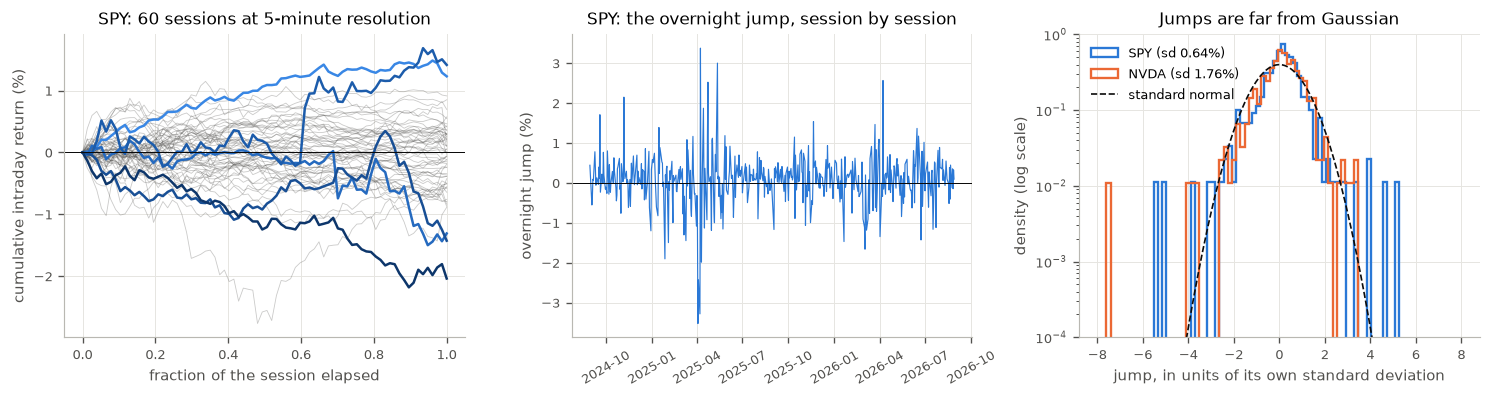

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
X5, grid5, dates5 = itd.session_curves(bars_5m[bars_5m["ticker"] == "SPY"])

# Every session, then the five largest by absolute close, so the fan does not hide the shapes.
for row in X5:
    axes[0].plot(grid5, 100 * row, color=style.MUTED, lw=0.5, alpha=0.3)
big = np.argsort(np.abs(X5[:, -1]))[-5:]
for rank, i in enumerate(big):
    axes[0].plot(grid5, 100 * X5[i], color=style.ordinal(5, lightest=6)[rank], lw=1.5)
axes[0].axhline(0, color=style.INK, lw=0.6)
axes[0].set_xlabel("fraction of the session elapsed")
axes[0].set_ylabel("cumulative intraday return (%)")
axes[0].set_title(f"SPY: {len(X5)} sessions at 5-minute resolution")

J_spy = itd.overnight_jumps(bars_1h[bars_1h["ticker"] == "SPY"])["jump"]
axes[1].plot(pd.to_datetime(J_spy.index), 100 * J_spy.to_numpy(),
             color=style.CATEGORICAL[0], lw=0.7)
axes[1].axhline(0, color=style.INK, lw=0.6)
axes[1].set_ylabel("overnight jump (%)")
axes[1].set_title("SPY: the overnight jump, session by session")
axes[1].tick_params(axis="x", rotation=30)

for sym, colour in (("SPY", style.CATEGORICAL[0]), ("NVDA", style.CATEGORICAL[1])):
    j = itd.overnight_jumps(bars_1h[bars_1h["ticker"] == sym])["jump"].to_numpy()
    axes[2].hist(j / j.std(), bins=60, histtype="step", lw=1.4, density=True,
                 color=colour, label=f"{sym} (sd {100 * j.std():.2f}%)")
z = np.linspace(-8, 8, 400)
axes[2].plot(z, stats.norm.pdf(z), color=style.INK, lw=1, ls="--", label="standard normal")
axes[2].set_yscale("log")
axes[2].set_ylim(1e-4, 1)
axes[2].set_xlabel("jump, in units of its own standard deviation")
axes[2].set_ylabel("density (log scale)")
axes[2].set_title("Jumps are far from Gaussian")
axes[2].legend()
plt.tight_layout()
plt.show()

## 2. Are overnight jumps serially correlated?

The first question is the simplest one, and it does not need functional data at all: given
last night's jump, is tonight's any more predictable? The same question is then asked of the
jump's *size*, which is a different question with a different answer.

In [4]:
def ljung_box(x, max_lag=5):
    """Sample autocorrelations to `max_lag` and the Ljung-Box p-value across them."""
    x = np.asarray(x, float) - np.mean(x)
    n = x.size
    r = np.array([np.sum(x[:-h] * x[h:]) / np.sum(x ** 2) for h in range(1, max_lag + 1)])
    q = n * (n + 2) * np.sum(r ** 2 / (n - np.arange(1, max_lag + 1)))
    return r, float(stats.chi2.sf(q, max_lag))


rows = []
for sym in itd.TICKERS:
    j = itd.overnight_jumps(bars_1h[bars_1h["ticker"] == sym])["jump"].to_numpy()
    r_signed, p_signed = ljung_box(j)
    r_abs, p_abs = ljung_box(np.abs(j))
    rows.append({"ticker": sym, "n": len(j), "acf1 J": r_signed[0], "LB p  J": p_signed,
                 "acf1 |J|": r_abs[0], "LB p  |J|": p_abs})
serial = pd.DataFrame(rows).set_index("ticker")
print(serial.round(4).to_string())
print(f"\nsigned jump  : {(serial['LB p  J'] < 0.05).sum()} of {len(serial)} "
      f"instruments reject independence at 5%")
print(f"absolute jump: {(serial['LB p  |J|'] < 0.05).sum()} of {len(serial)} "
      f"instruments reject independence at 5%")

          n  acf1 J  LB p  J  acf1 |J|  LB p  |J|
ticker                                           
AAPL    493  0.1036   0.0916    0.2373     0.0000
AMZN    493  0.1383   0.0617    0.2395     0.0000
MSFT    493  0.0312   0.6216    0.0782     0.0373
NVDA    493 -0.0053   0.5680    0.0703     0.0000
TSLA    493 -0.0468   0.1697    0.0611     0.0089
SPY     493  0.0680   0.6882    0.2106     0.0000
QQQ     493  0.0354   0.6362    0.1015     0.0000
^GSPC   493  0.0567   0.7995    0.1547     0.0000
^FTSE   499  0.0664   0.1402    0.0388     0.0094

signed jump  : 0 of 9 instruments reject independence at 5%
absolute jump: 9 of 9 instruments reject independence at 5%


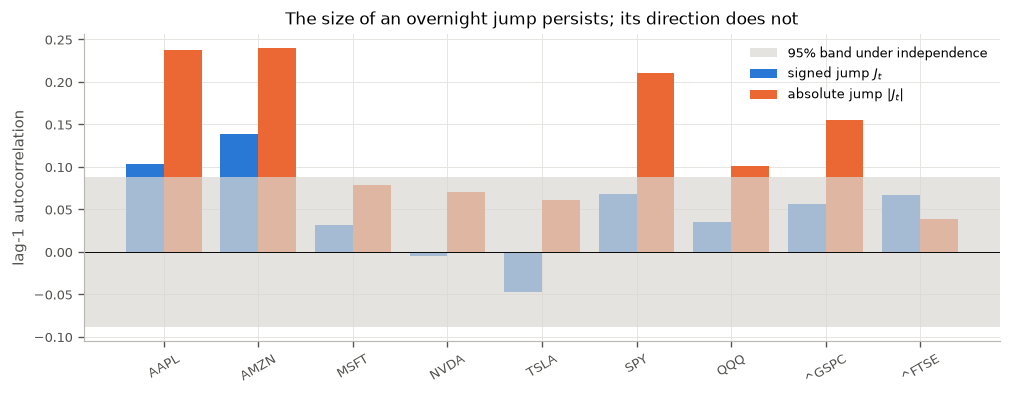

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
pos = np.arange(len(serial))
ax.bar(pos - 0.2, serial["acf1 J"], width=0.4, color=style.CATEGORICAL[0],
       label=r"signed jump $J_t$")
ax.bar(pos + 0.2, serial["acf1 |J|"], width=0.4, color=style.CATEGORICAL[1],
       label=r"absolute jump $|J_t|$")
band = 1.96 / np.sqrt(serial["n"].to_numpy().mean())
ax.axhspan(-band, band, color=style.BAND, alpha=0.7, lw=0,
           label="95% band under independence")
ax.axhline(0, color=style.INK, lw=0.6)
ax.set_axisbelow(True)
ax.set_xticks(pos)
ax.set_xticklabels(serial.index, rotation=30)
ax.set_ylabel("lag-1 autocorrelation")
ax.set_title("The size of an overnight jump persists; its direction does not")
ax.legend()
plt.tight_layout()
plt.show()

This is the shape of every answer in the notebook, arriving early. The **direction** of the
overnight move is close to unforecastable from its own past: the lag-1 autocorrelations sit
inside the band a coin flip would produce, and the Ljung-Box test rejects for none of the nine
instruments at the 5% level. The **size** is strongly persistent, rejecting for all nine, with
lag-1 autocorrelations up to about a quarter.

That is volatility clustering, and it is not news. What is worth doing is checking whether it
is also the whole content of the functional analysis that follows, which turns out to be the
case.

### Jumps happen together

Before leaving the scalars: the overnight jumps of different instruments are not independent
of each other, even though each is unpredictable from its own past.

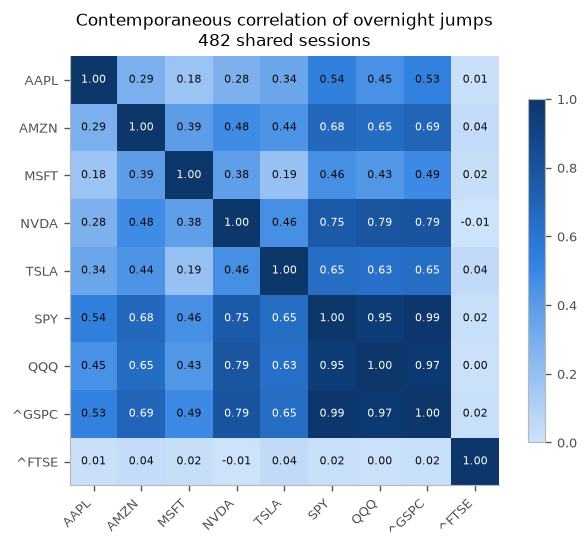

mean off-diagonal correlation, US names only: 0.553
mean correlation of ^FTSE with the US names : 0.017


In [6]:
jump_frame = pd.DataFrame({
    sym: itd.overnight_jumps(bars_1h[bars_1h["ticker"] == sym])["jump"]
    for sym in itd.TICKERS
}).dropna()
corr = jump_frame.corr()

fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr.to_numpy(), cmap=style.SEQUENTIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for k in range(len(corr)):
        v = corr.iloc[i, k]
        ax.text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if v > 0.6 else style.INK)
ax.set_title(f"Contemporaneous correlation of overnight jumps\n{len(jump_frame)} shared "
             f"sessions")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

off = corr.to_numpy()[np.triu_indices(len(corr), 1)]
us = corr.drop(index="^FTSE", columns="^FTSE").to_numpy()
print(f"mean off-diagonal correlation, US names only: "
      f"{us[np.triu_indices(len(us), 1)].mean():.3f}")
print(f"mean correlation of ^FTSE with the US names : "
      f"{corr.loc['^FTSE'].drop('^FTSE').mean():.3f}")

The US names all jump together — one market-wide factor, with SPY and `^GSPC` essentially the
same series — while `^FTSE` is uncorrelated with all of them. That is the stale-opening-print
artefact showing up a second time, from a completely different direction, and it is worth
noting as a data-quality check rather than a finding: a genuine London opening move would be
strongly correlated with the US overnight move, because the two markets respond to the same
news.

## 3. Is the sequence of intraday curves a FAR(1)?

Now the functional question. A FAR(1) model,

$$ X_t(s) = \int_0^1 \psi(s, r)\, X_{t-1}(r)\, dr + \varepsilon_t(s), $$

says that today's whole intraday shape is a linear function of yesterday's. `far.far_est`
fits $\psi$ by projecting onto principal components and regressing each score vector on its
predecessor, and tests for any serial dependence two ways: a chi-squared portmanteau
statistic on the scores, and a permutation reference that reshuffles the curves — which *is*
the i.i.d. null exactly, conditional on the observed curves, and needs no moment assumption.
Price curves are heavy tailed, so the second is the one to believe where they disagree.

In [7]:
rows = []
for sym in itd.TICKERS:
    X, grid, _ = itd.session_curves(bars_1h[bars_1h["ticker"] == sym])
    p_hat = est.select_p(X, grid, p_range=range(1, 6))["p_hat"]
    fit = est.far1_fit(X, grid, p=p_hat)
    rows.append({
        "ticker": sym, "n": len(X), "p": p_hat,
        "||psi||_HS": fit["hs_norm"], "in-sample R2": fit["r2"],
        "chi2 p": est.portmanteau_test(X, grid, max_lag=5, n_components=3)["p_value"],
        "perm p": est.permutation_test(X, grid, max_lag=5, n_perm=499, rng=1)["p_value"],
        "OOS R2": est.rolling_forecast(X, grid, p=p_hat)["r2_oos"],
    })
far_table = pd.DataFrame(rows).set_index("ticker")
print(far_table.round(4).to_string())
print(f"\nreject independence at 5%: {(far_table['perm p'] < 0.05).sum()} of "
      f"{len(far_table)} by permutation, "
      f"{(far_table['chi2 p'] < 0.05).sum()} by chi-squared")
print(f"beat the flat forecast out of sample: {(far_table['OOS R2'] > 0).sum()} of "
      f"{len(far_table)}")

          n  p  ||psi||_HS  in-sample R2  chi2 p  perm p  OOS R2
ticker                                                          
AAPL    494  1      0.1147        0.0112  0.0000   0.002 -0.0507
AMZN    494  1      0.1859        0.0285  0.0000   0.002 -0.0027
MSFT    494  3      0.4115        0.0086  0.0011   0.020 -0.0340
NVDA    494  3      0.6081        0.0487  0.0001   0.002 -0.0165
TSLA    494  2      0.3263        0.0274  0.0285   0.020  0.0003
SPY     494  3      0.5865        0.0652  0.0000   0.002 -0.1300
QQQ     494  3      0.4968        0.0499  0.0000   0.002 -0.0821
^GSPC   494  3      0.6054        0.0655  0.0000   0.002 -0.1287
^FTSE   500  1      0.0913        0.0067  0.0419   0.096  0.0069

reject independence at 5%: 8 of 9 by permutation, 9 by chi-squared
beat the flat forecast out of sample: 2 of 9


Both tests reject independence almost everywhere, and the fitted operator beats the flat
forecast out of sample for only two instruments, by margins under a percentage point. Those
two facts are not in conflict, and the gap between them is the interesting part: **the curves are demonstrably dependent, and a FAR(1) cannot use
that dependence.**

The next cell shows why.

In [8]:
sym = "SPY"
X, grid, _ = itd.session_curves(bars_1h[bars_1h["ticker"] == sym])
w = np.trapezoid(np.eye(grid.size), grid, axis=0)
norms = np.sqrt(np.sum(X ** 2 * w, axis=1))
shape = X / np.where(norms[:, None] > 0, norms[:, None], 1.0)   # direction only, unit norm

rows = []
for s in itd.TICKERS:
    Xs, gs, _ = itd.session_curves(bars_1h[bars_1h["ticker"] == s])
    ws = np.trapezoid(np.eye(gs.size), gs, axis=0)
    ns = np.sqrt(np.sum(Xs ** 2 * ws, axis=1))
    unit = Xs / np.where(ns[:, None] > 0, ns[:, None], 1.0)
    rows.append({
        "ticker": s,
        "perm p, curve": est.permutation_test(Xs, gs, max_lag=5, n_perm=499,
                                              rng=1)["p_value"],
        "perm p, direction only": est.permutation_test(unit, gs, max_lag=5, n_perm=499,
                                                       rng=1)["p_value"],
        "acf1 of ||X_t||": ljung_box(ns)[0][0],
        "LB p of ||X_t||": ljung_box(ns)[1],
    })
scale_table = pd.DataFrame(rows).set_index("ticker")
print(scale_table.round(4).to_string())
print(f"\nwith the scale divided out, dependence survives in "
      f"{(scale_table['perm p, direction only'] < 0.05).sum()} of {len(scale_table)} "
      f"instruments,")
print(f"down from {(scale_table['perm p, curve'] < 0.05).sum()}. "
      f"The norm ||X_t|| is autocorrelated in "
      f"{(scale_table['LB p of ||X_t||'] < 0.05).sum()} of {len(scale_table)}.")

        perm p, curve  perm p, direction only  acf1 of ||X_t||  LB p of ||X_t||
ticker                                                                         
AAPL            0.002                   0.548           0.3778              0.0
AMZN            0.002                   0.008           0.2869              0.0
MSFT            0.020                   0.612           0.2574              0.0
NVDA            0.002                   0.282           0.3346              0.0
TSLA            0.020                   0.670           0.1991              0.0
SPY             0.002                   0.722           0.4762              0.0
QQQ             0.002                   0.730           0.4199              0.0
^GSPC           0.002                   0.792           0.4754              0.0
^FTSE           0.096                   0.786           0.3340              0.0

with the scale divided out, dependence survives in 1 of 9 instruments,
down from 8. The norm ||X_t|| is autocorrelated 

Dividing every curve by its own norm keeps the *shape* of the session and throws away *how far
it moved*. Doing that removes the serial dependence almost everywhere, while the norms
themselves are strongly autocorrelated in every instrument.

So the dependence the portmanteau test found is volatility clustering wearing functional
clothes. A FAR(1) is a model for the conditional *mean* of the next curve, and there is
nothing there: the direction of tomorrow's session is independent of today's. What persists
is the conditional *variance*, which no linear operator on the curve can express — hence
significant tests and a negative out-of-sample $R^2$ at the same time.

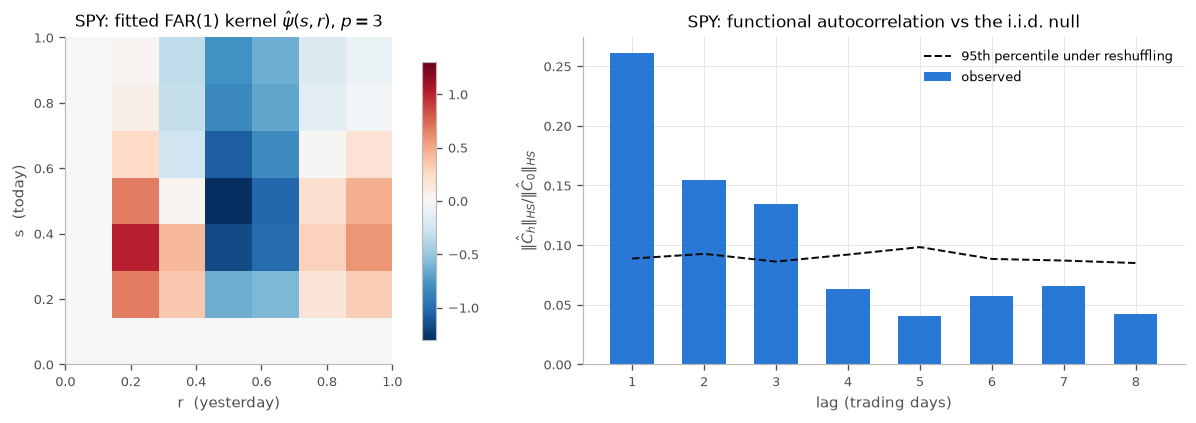

SPY: permutation p-value = 0.0010, out-of-sample R2 of the fitted FAR(1) = -0.1300


In [9]:
fit = est.far1_fit(X, grid, p=3)
acf = est.acf_norms(X, grid, max_lag=8)
perm = est.permutation_test(X, grid, max_lag=8, n_perm=999, rng=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
lim = np.abs(fit["kernel"]).max()
im = ax[0].imshow(fit["kernel"], origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r",
                  vmin=-lim, vmax=lim)
ax[0].grid(False)
ax[0].set_xlabel("r  (yesterday)")
ax[0].set_ylabel("s  (today)")
ax[0].set_title(fr"{sym}: fitted FAR(1) kernel $\hat\psi(s, r)$, $p = 3$")
plt.colorbar(im, ax=ax[0], shrink=0.85)

lags = np.arange(1, acf.size + 1)
ax[1].set_axisbelow(True)
ax[1].bar(lags, acf, color=style.CATEGORICAL[0], width=0.6, label="observed")
ax[1].plot(lags, perm["band"], color=style.INK, ls="--", lw=1.2,
           label="95th percentile under reshuffling")
ax[1].set_xlabel("lag (trading days)")
ax[1].set_ylabel(r"$\|\hat C_h\|_{HS} / \|\hat C_0\|_{HS}$")
ax[1].set_title(f"{sym}: functional autocorrelation vs the i.i.d. null")
ax[1].legend()
plt.tight_layout()
plt.show()

print(f"{sym}: permutation p-value = {perm['p_value']:.4f}, "
      f"out-of-sample R2 of the fitted FAR(1) = "
      f"{est.rolling_forecast(X, grid, p=3)['r2_oos']:+.4f}")

## 4. Does the previous session's curve predict the jump?

The FAR(1) asks whether the curve predicts the next *curve*. The question this notebook is
actually about is whether it predicts the next *jump*, which is a scalar-on-function
regression and exactly the problem `fdaSP.SBC` and `truncFLR` solve.

Nine instruments are pooled to get the sample size up, each divided by its own standard
deviation first so that the volatile names do not swamp the rest. Folds are blocked by
calendar date: rows from the same day but different tickers share that day's market-wide move,
so a random split would test the model on near-copies of its own training set.

In [10]:
def holdout_r2(X, y, grid, folds, lam, n_basis=8, Z=None):
    """Out-of-sample R^2 at a fixed penalty, refitting inside each fold."""
    pred = np.empty_like(y)
    for f in np.unique(folds):
        te, tr = folds == f, folds != f
        mu = y[tr].mean()
        fit = SBC.fit(X[tr], y[tr] - mu, grid, lam, Z=None if Z is None else Z[tr],
                      n_basis=n_basis, order=4)
        pred[te] = SBC.predict(fit, X[te], grid, Z=None if Z is None else Z[te]) + mu
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2), pred


results = []
for panel in ("1h", "5m"):
    for target in ("signed", "absolute"):
        d = itd.stack_panel(panel, kind="cidr", target=target)
        X_p, y_p, grid_p, dates_p = d["X"], d["y"], d["grid"], d["date"]
        folds = itd.date_blocked_folds(dates_p, 10)
        cv = SBC.cv_fit(X_p, y_p - y_p.mean(), grid_p, n_basis=8, order=4, n_lambda=40,
                        folds=folds, n_folds=10)
        r2, _ = holdout_r2(X_p, y_p, grid_p, folds, cv["lam_hat"])
        results.append({"panel": panel, "target": target, "n": len(y_p),
                        "dates": len(set(dates_p.tolist())), "lambda": cv["lam_hat"],
                        "% zeroed": 100 * np.mean(~cv["support"]), "OOS R2": r2})
print(pd.DataFrame(results).round(4).to_string(index=False))

panel   target    n  dates  lambda  % zeroed  OOS R2
   1h   signed 4443    510 25.8068     100.0 -0.0048
   1h absolute 4443    510 29.5122     100.0 -0.0092
   5m   signed  530     61  3.2192     100.0 -0.0086
   5m absolute  530     61  1.7667     100.0 -0.0166


Nothing. On both panels and for both targets the cross-validated group lasso sets the
coefficient function to zero over essentially the whole session, and the out-of-sample $R^2$
is at or below zero — a fitted model doing no better than predicting the average.

This is the estimator behaving exactly as it should. It is not being asked to find a null
region inside a real signal; it is being asked whether there is a signal, and it answers by
zeroing the domain. The truncated model agrees: no retained window predicts better than any
other, because none of them predicts.

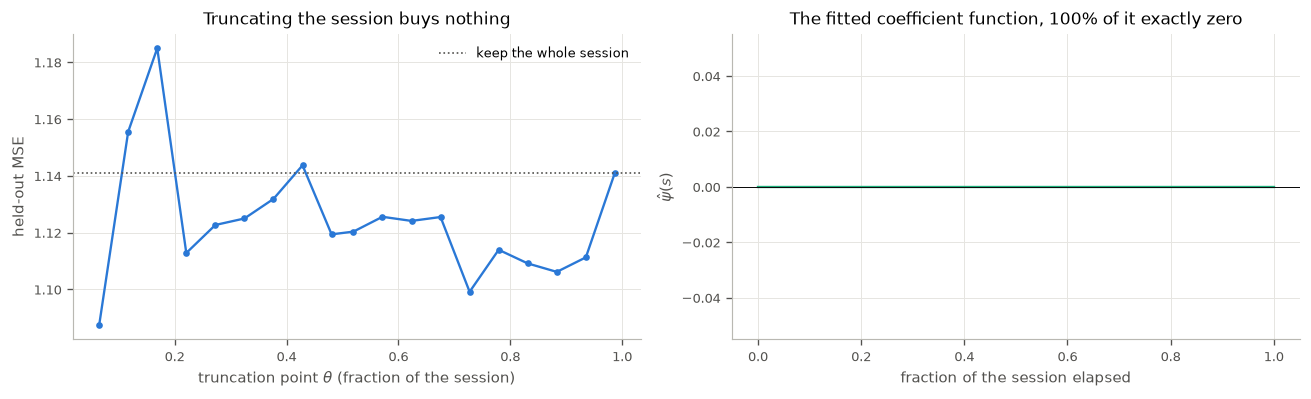

best held-out MSE over all truncations: 1.0873
held-out MSE keeping the whole session: 1.1411


In [11]:
d = itd.stack_panel("5m", kind="cidr", target="signed")
folds = itd.date_blocked_folds(d["date"], 10)
prof_null = HH_A.truncation_profile(d["X"], d["y"] - d["y"].mean(), d["grid"], folds=folds)
good = np.isfinite(prof_null["mse"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(prof_null["thetas"][good], prof_null["mse"][good],
           color=style.METHOD_COLOUR["HH-A"], marker=".")
ax[0].axhline(prof_null["mse_full"], color=style.MUTED, ls=":", lw=1,
              label="keep the whole session")
ax[0].set_xlabel(r"truncation point $\theta$ (fraction of the session)")
ax[0].set_ylabel("held-out MSE")
ax[0].set_title("Truncating the session buys nothing")
ax[0].legend()

cv_null = SBC.cv_fit(d["X"], d["y"] - d["y"].mean(), d["grid"], n_basis=8, order=4,
                     n_lambda=40, folds=folds, n_folds=10)
ax[1].plot(d["grid"], cv_null["beta"], color=style.METHOD_COLOUR["OGL"])
ax[1].axhline(0, color=style.INK, lw=0.6)
ax[1].set_xlabel("fraction of the session elapsed")
ax[1].set_ylabel(r"$\hat\psi(s)$")
ax[1].set_title(f"The fitted coefficient function, "
                f"{100 * np.mean(~cv_null['support']):.0f}% of it exactly zero")
plt.tight_layout()
plt.show()

print(f"best held-out MSE over all truncations: {np.nanmin(prof_null['mse']):.4f}")
print(f"held-out MSE keeping the whole session: {prof_null['mse_full']:.4f}")

## 5. What does help: the size, not the sign

Section 2 already said where to look. The size of the jump persists, so the natural covariate
is something measuring how much the previous day moved. `fdaSP.intraday` supplies three:
the realised volatility of the session, its Parkinson range, and the previous jump's own size.

In [12]:
rows = []
for sym in itd.TICKERS:
    one = bars_1h[bars_1h["ticker"] == sym]
    jumps = itd.overnight_jumps(one)
    summary = itd.session_summary(one)
    pos = {d: i for i, d in enumerate(summary.index)}

    aligned = [(abs(jumps.loc[d, "jump"]), summary["rvol"].iloc[pos[d] - 1],
                summary["rng"].iloc[pos[d] - 1])
               for d in jumps.index if pos.get(d, 0) > 0]
    a = np.array(aligned)
    prev_size = np.abs(jumps["jump"].to_numpy())
    rows.append({
        "ticker": sym,
        "|J_t| ~ |J_{t-1}|": np.corrcoef(prev_size[1:], prev_size[:-1])[0, 1],
        "|J_t| ~ rvol_{t-1}": np.corrcoef(a[:, 0], a[:, 1])[0, 1],
        "|J_t| ~ range_{t-1}": np.corrcoef(a[:, 0], a[:, 2])[0, 1],
    })
size_table = pd.DataFrame(rows).set_index("ticker")
print(size_table.round(3).to_string())
print("\nmean across instruments:")
print(size_table.mean().round(3).to_string())

        |J_t| ~ |J_{t-1}|  |J_t| ~ rvol_{t-1}  |J_t| ~ range_{t-1}
ticker                                                            
AAPL                0.237               0.249                0.281
AMZN                0.240               0.233                0.206
MSFT                0.078               0.171                0.174
NVDA                0.070               0.221                0.265
TSLA                0.061               0.186                0.242
SPY                 0.211               0.356                0.413
QQQ                 0.102               0.285                0.310
^GSPC               0.155               0.346                0.400
^FTSE               0.039               0.174                0.170

mean across instruments:
|J_t| ~ |J_{t-1}|      0.132
|J_t| ~ rvol_{t-1}     0.247
|J_t| ~ range_{t-1}    0.274


The previous session's **range** is the best of the three, correlating with the size of the
coming jump at about 0.27 on average and above 0.4 for the two broad-market instruments. That
is a real, sizeable relationship, and it is the first thing in this notebook that predicts
anything.

It also sets up the one genuinely functional question worth asking of it. The running realised
volatility of a session is a curve, $V_t(s)$, increasing from zero, whose endpoint is the
session's realised volatility. Does the *shape* of that curve add anything beyond its
endpoint — does it matter *when* in the day the movement happened?

In [13]:
d = itd.stack_panel("1h", kind="rvol", target="absolute")
X_v, y_v, grid_v, dates_v = d["X"], d["y"], d["grid"], d["date"]
folds_v = itd.date_blocked_folds(dates_v, 10)
rv_end = X_v[:, -1:]                                 # the scalar realised volatility


def scalar_r2(Z):
    pred = np.empty_like(y_v)
    for f in np.unique(folds_v):
        te, tr = folds_v == f, folds_v != f
        A = np.column_stack([np.ones(tr.sum()), Z[tr]])
        coef = np.linalg.lstsq(A, y_v[tr], rcond=None)[0]
        pred[te] = np.column_stack([np.ones(te.sum()), Z[te]]) @ coef
    return 1 - np.sum((y_v - pred) ** 2) / np.sum((y_v - y_v.mean()) ** 2), pred


def functional_r2(Z=None, n_basis=6):
    cv = SBC.cv_fit(X_v, y_v - y_v.mean(), grid_v, Z=Z, n_basis=n_basis, order=4,
                    n_lambda=40, folds=folds_v, n_folds=10)
    r2, pred = holdout_r2(X_v, y_v, grid_v, folds_v, cv["lam_hat"], n_basis, Z=Z)
    return r2, pred, cv


print(f"pooled 1h panel: n = {len(y_v)} rows over "
      f"{len(set(dates_v.tolist()))} dates\n")
print(f"{'model for |J_t|':44s}{'OOS R2':>9}{'Spearman':>10}")
scores = {}
for name, r2, pred in [
        ("scalar: previous session's realised volatility", *scalar_r2(rv_end)),
        ("functional: the whole running-volatility curve", *functional_r2()[:2]),
        ("functional curve, with the endpoint in z", *functional_r2(Z=rv_end)[:2])]:
    scores[name] = r2
    print(f"{name:44s}{r2:+9.4f}{stats.spearmanr(pred, y_v).statistic:+10.3f}")

pooled 1h panel: n = 4443 rows over 510 dates

model for |J_t|                                OOS R2  Spearman


scalar: previous session's realised volatility  +0.0508    +0.199
functional: the whole running-volatility curve  +0.0136    +0.116
functional curve, with the endpoint in z      +0.0144    +0.114


The functional predictor is **worse than its own endpoint**. Handing the estimator the whole
volatility path, rather than the single number at the end of it, costs out-of-sample accuracy.

That is not a failure of the estimator; it is a statement about where the information sits. A
scalar-on-function term $\int X(s)\psi(s)\,ds$ with $\psi$ a bounded function cannot pick out
$X(1)$ — evaluation at a point is not an integral against anything. When the informative
summary of a curve is one of its values, the functional term is the wrong instrument, and what
is needed is precisely the unpenalised scalar slot $z^\top\gamma$ that the Stefanucci model
(their equation 62.1) carries alongside it. That term is usually treated as a place to put
nuisance covariates; here it is where the signal lives, and the functional term is the
nuisance.

### Does the fold blocking matter?

Every cross-validated number above uses folds blocked by calendar date, on the argument that
rows sharing a date share that day's market-wide move and rows from adjacent days share a
volatility regime. That argument is worth measuring rather than asserting, and this is the
one design in the notebook with enough signal for leakage to have something to inflate.

In [14]:
rng = np.random.default_rng(0)
folds_random = rng.permutation(len(y_v)) % 10

for label, folds in (("random folds", folds_random), ("blocked by date", folds_v)):
    cv = SBC.cv_fit(X_v, y_v - y_v.mean(), grid_v, n_basis=6, order=4, n_lambda=40,
                    folds=folds, n_folds=10)
    pred = np.empty_like(y_v)
    for f in np.unique(folds):
        te, tr = folds == f, folds != f
        mu = y_v[tr].mean()
        fit = SBC.fit(X_v[tr], y_v[tr] - mu, grid_v, cv["lam_hat"], n_basis=6, order=4)
        pred[te] = SBC.predict(fit, X_v[te], grid_v) + mu
    r2 = 1 - np.sum((y_v - pred) ** 2) / np.sum((y_v - y_v.mean()) ** 2)
    print(f"{label:16s} best CV MSE = {cv['cv_mean'].min():.4f}, "
          f"out-of-sample R2 = {r2:+.4f}")

random folds     best CV MSE = 0.5704, out-of-sample R2 = +0.0316


blocked by date  best CV MSE = 0.5784, out-of-sample R2 = +0.0136


Random folds report the lower error and more than twice the apparent skill: an out-of-sample
$R^2$ of $+0.0316$ against $+0.0136$ once the folds respect the calendar.

The two numbers are separated by where the leak is. The cross-validated error itself differs
by under two per cent, so the damage is barely visible in the quantity used to *select*
$\lambda$; it is the quantity used to *report* performance that doubles. And the mechanism
here is cross-sectional rather than temporal. Nine instruments contribute a row each on every
date, and those nine rows share that date's market-wide move, so a random split puts eight
near-copies of every test row into the training set. That is a much harder leak to survive
than the overlapping-window case, where consecutive rows merely share raw observations.

Blocking by date is therefore not a formality on this panel. It is the difference between
reporting that the previous session's volatility explains 3% of the variation in the size of
the coming jump and reporting that it explains 1.4%.

## 6. The sign, after all: borrowing another market's session

Everything above says the *direction* of the overnight jump is unpredictable. That conclusion
was drawn from information available at the New York close, which is the wrong place to stop
looking, because the New York night is not empty. London trades through it.

The London session runs 08:00–16:30 local, which is 03:00–11:30 in New York, so most of it
falls inside the window between the New York close and the next New York open. Its early hours
are genuinely observable before New York opens, and they respond to the same overnight news.

Timing has to be exact for this to be a forecast rather than a look-ahead. New York opens at
09:30 local, which is 14:30 London for most of the year and 13:30 during the three weeks in
spring and autumn when the two daylight-saving switches are out of step. Everything below uses
the London session **up to 13:00 only**, which is before the New York open under either
offset, with an hour to spare.

In [15]:
CUTOFF = "13:00"
ftse = bars_1h[bars_1h["ticker"] == "^FTSE"]
R, grid_am, dates_am = itd.session_curves(ftse, kind="ret", until=CUTOFF)

session_hours = 8.5           # the London session, 08:00 to 16:30
kept_hours = 5.0              # 08:00 to the 13:00 cutoff


def london_clock(s):
    """Position on the truncated curve -> London wall-clock hour."""
    return 8.0 + kept_hours * s


rows = []
for sym in itd.TICKERS:
    if sym == "^FTSE":
        continue
    jumps = itd.overnight_jumps(bars_1h[bars_1h["ticker"] == sym])["jump"]
    Xf, yf, when = itd.align_curves_to_series(R, dates_am, jumps, offset=0)
    total = np.trapezoid(Xf, grid_am, axis=1)          # the London morning move
    r, p = stats.pearsonr(total, yf)
    rows.append({"ticker": sym, "n": len(yf), "corr": r, "p-value": p,
                 "Spearman": stats.spearmanr(total, yf).statistic, "R2": r ** 2})
lead = pd.DataFrame(rows).set_index("ticker")
print(lead.round(4).to_string())
print(f"\nsignificant at 5%: {(lead['p-value'] < 0.05).sum()} of {len(lead)} instruments")

          n    corr  p-value  Spearman      R2
ticker                                        
AAPL    482  0.1623   0.0003    0.1283  0.0263
AMZN    482  0.1528   0.0008    0.1421  0.0234
MSFT    482  0.0777   0.0882    0.1139  0.0060
NVDA    482  0.1737   0.0001    0.1809  0.0302
TSLA    482  0.0971   0.0330    0.1232  0.0094
SPY     482  0.2721   0.0000    0.2390  0.0740
QQQ     482  0.2376   0.0000    0.2066  0.0565
^GSPC   482  0.2505   0.0000    0.2150  0.0628

significant at 5%: 7 of 8 instruments


The direction of the US overnight jump *is* predictable, from a market that was open while
New York was not. For SPY the correlation is 0.272 over 482 nights, which no amount of
multiple testing explains away, and it is significant for seven of the eight instruments.

Note what this does and does not say. It is not an arbitrage: the London move is a response to
the same news that moves New York, so this is a measurement of how news propagates between
markets, not a free lunch. What makes it worth this notebook is that it turns the overnight
jump from something with no predictor into something with one, and that predictor is a
*curve* — which lets the two estimators say something about it.

In [16]:
jumps_spy = itd.overnight_jumps(bars_1h[bars_1h["ticker"] == "SPY"])["jump"]
Xf, yf, when = itd.align_curves_to_series(R, dates_am, jumps_spy, offset=0)
yf = yf / yf.std()
folds_f = itd.date_blocked_folds(when, 10)
yfc = yf - yf.mean()

cv_f = SBC.cv_fit(Xf, yfc, grid_am, n_basis=6, order=4, n_lambda=40,
                  folds=folds_f, n_folds=10)
r2_f, _ = holdout_r2(Xf, yf, grid_am, folds_f, cv_f["lam_hat"], n_basis=6)
print(f"n = {len(yf)} nights, {when[0]} to {when[-1]}")
print(f"OGL: lambda = {cv_f['lam_hat']:.4g}, "
      f"{100 * np.mean(~cv_f['support']):.0f}% of the morning zeroed, "
      f"out-of-sample R2 = {r2_f:+.4f}")

prof_f = HH_A.truncation_profile(Xf, yfc, grid_am, folds=folds_f)
ok = np.isfinite(prof_f["mse"])
print(f"truncation profile: best held-out MSE {np.nanmin(prof_f['mse']):.4f} at "
      f"{london_clock(prof_f['theta_hat']):.2f}h London, "
      f"against {prof_f['mse_full']:.4f} keeping the whole morning")
print(f"the profile spans {prof_f['mse'][ok].min():.4f} to {prof_f['mse'][ok].max():.4f}, "
      f"a range of {100 * (prof_f['mse'][ok].max() / prof_f['mse'][ok].min() - 1):.1f}%")

n = 482 nights, 2024-08-30 to 2026-08-28
OGL: lambda = 0.01837, 0% of the morning zeroed, out-of-sample R2 = +0.0424


truncation profile: best held-out MSE 0.9760 at 11.17h London, against 1.0128 keeping the whole morning
the profile spans 0.9760 to 1.0167, a range of 4.2%


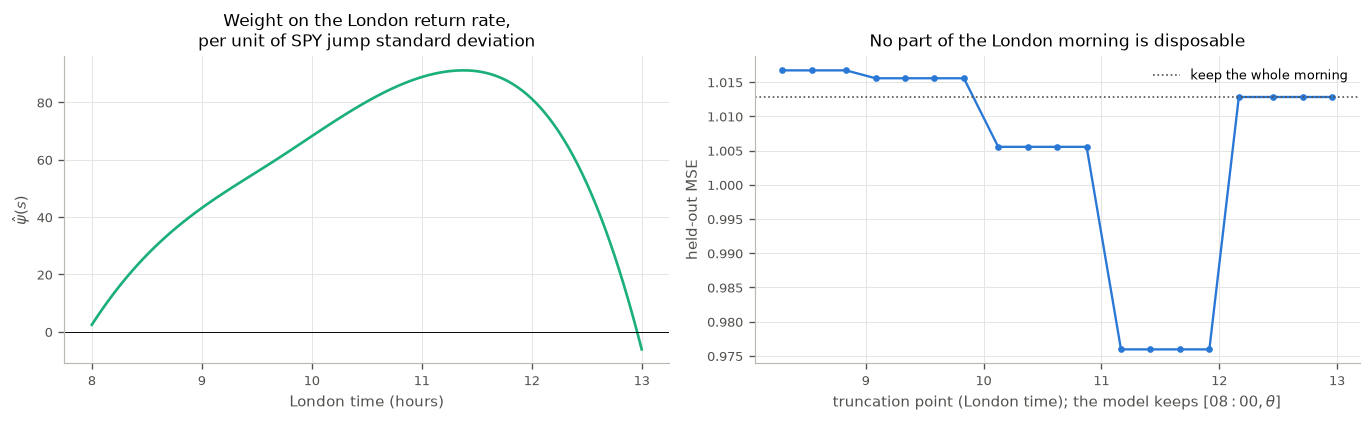

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))

hours = london_clock(grid_am)
ax[0].plot(hours, cv_f["beta"], color=style.METHOD_COLOUR["OGL"], lw=1.6)
ax[0].axhline(0, color=style.INK, lw=0.6)
for a, b in SBC.find_regions(~cv_f["support"], grid_am):
    ax[0].axvspan(london_clock(a), london_clock(b), color=style.BAND, alpha=0.8, lw=0)
ax[0].set_xlabel("London time (hours)")
ax[0].set_ylabel(r"$\hat\psi(s)$")
ax[0].set_title("Weight on the London return rate,\nper unit of SPY jump standard deviation")

ax[1].plot(london_clock(prof_f["thetas"][ok]), prof_f["mse"][ok],
           color=style.METHOD_COLOUR["HH-A"], marker=".")
ax[1].axhline(prof_f["mse_full"], color=style.MUTED, ls=":", lw=1,
              label="keep the whole morning")
ax[1].set_xlabel(r"truncation point (London time); the model keeps $[08{:}00, \theta]$")
ax[1].set_ylabel("held-out MSE")
ax[1].set_title("No part of the London morning is disposable")
ax[1].legend()
plt.tight_layout()
plt.show()

Both estimators say the same thing, which is that there is nothing local to find here. The
group lasso zeroes none of the morning, and the truncated model's held-out error varies by a
few per cent across every candidate endpoint, with no elbow. The information about tonight's
New York open accumulates steadily through the London morning rather than arriving in a
particular hour of it.

That is a negative result about *structure* sitting on top of a positive result about
*signal*, and it is worth separating the two. The signal is real and out-of-sample. Its
coefficient function is close to flat, which is to say the useful summary of the London
morning is very nearly just its total move — the same lesson as the volatility curve in
section 5, reached from the opposite direction.

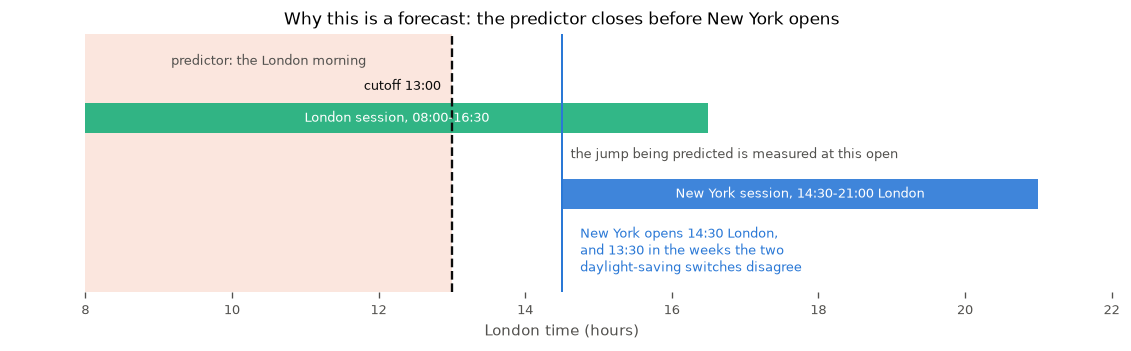

In [18]:
fig, ax = plt.subplots(figsize=(9.5, 3.0))

# The predictor window, drawn behind both sessions.
ax.axvspan(8.0, 13.0, color=style.CATEGORICAL[1], alpha=0.16, lw=0)

spans = [("London session, 08:00-16:30", 8.0, 16.5, 1, style.CATEGORICAL[2]),
         ("New York session, 14:30-21:00 London", 14.5, 21.0, 0, style.CATEGORICAL[0])]
for label, a, b, row, colour in spans:
    ax.barh(row, b - a, left=a, height=0.4, color=colour, alpha=0.9)
    ax.text((a + b) / 2, row, label, ha="center", va="center", color="white", fontsize=8)

ax.axvline(13.0, color=style.INK, ls="--", lw=1.4)
ax.axvline(14.5, color=style.CATEGORICAL[0], lw=1.2)

ax.annotate("predictor: the London morning", (10.5, 1.75), ha="center", va="center",
            fontsize=8, color=style.MUTED)
ax.annotate("cutoff 13:00", (12.85, 1.42), ha="right", va="center", fontsize=8,
            color=style.INK)
ax.annotate("New York opens 14:30 London,\nand 13:30 in the weeks the two\n"
            "daylight-saving switches disagree",
            (14.75, -0.75), ha="left", va="center", fontsize=8,
            color=style.CATEGORICAL[0])
ax.annotate("the jump being predicted is measured at this open", (14.62, 0.52),
            ha="left", va="center", fontsize=8, color=style.MUTED)

ax.set_yticks([])
ax.set_xlim(7, 22)
ax.set_ylim(-1.3, 2.1)
ax.set_xlabel("London time (hours)")
ax.set_title("Why this is a forecast: the predictor closes before New York opens")
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## Summary

**The direction of an overnight jump is unpredictable from the market's own past; its size is
not.** Over about 500 sessions each, the Ljung-Box test rejects independence of the signed
jump for none of the nine instruments and of the absolute jump for all nine, with lag-1
autocorrelations in the size reaching about a quarter.

**The intraday curve process rejects independence, and a FAR(1) still cannot forecast it.**
A chi-squared portmanteau test on the principal component scores rejects for all nine
instruments and a permutation reference for eight, while the fitted operator beats a flat
forecast out of sample for only two, by margins under a percentage point. Dividing each curve
by its own norm — keeping the shape of the session and discarding how far it moved — removes
the dependence in seven of the eight where it was present, while the norms themselves are
autocorrelated in all nine. The dependence is volatility
clustering, which lives in the conditional variance, and a FAR(1) is a model of the
conditional mean.

**The previous session's curve does not predict the jump that follows it.** Pooled across
instruments with date-blocked folds, on both panels and for both the signed and the absolute
jump, the cross-validated group lasso zeroes essentially the whole domain and the out-of-sample
$R^2$ is at or below zero. The truncated model finds no window that predicts better than any
other.

**Of the covariates that do help, the useful ones are scalars, and that is a statement about
the model rather than about the data.** The previous session's Parkinson range correlates with
the size of the coming jump at about 0.27 on average, above 0.4 for the broad-market
instruments. Given the whole running-volatility curve, the group lasso does *worse*
out-of-sample than a regression on that curve's endpoint alone, because a bounded $\psi$
integrated against $X$ cannot evaluate $X$ at a point. When the informative summary of a curve
is one of its values, the signal belongs in the model's scalar term $z^\top\gamma$ and not in
its functional one.

**Blocking the folds by date is load-bearing on a pooled panel.** Nine instruments contribute
a row each on every date and share that date's market-wide move, so a random split puts eight
near-copies of every test row into the training set. On the one design here with signal to
inflate, random folds report more than twice the out-of-sample $R^2$ that date-blocked folds
do, while the cross-validated error used to select $\lambda$ differs by under two per cent —
the leak shows up in the reported number, not in the selected model.

**The sign becomes predictable once the search widens past the market's own history.** The
London morning, truncated at 13:00 so that it closes before New York opens under either
daylight-saving offset, predicts the US overnight jump for seven of eight instruments —
correlation 0.272 for SPY over 482 nights, and above 0.23 for the two other broad-market
instruments. This is news propagating between markets rather than an inefficiency. Neither
estimator finds any structure inside it: the group lasso zeroes none of the morning and the
truncation profile has no elbow, so the information accumulates steadily through the session
and the useful summary is again close to the total move.